In [ ]:
import os
import itertools
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Dense, Dropout, Embedding, Input, MultiHeadAttention, LayerNormalization, Layer
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, normalizers

tf.keras.mixed_precision.set_global_policy("mixed_float16")
print("Compute dtype:", tf.keras.mixed_precision.global_policy().compute_dtype)
print("Variable dtype:", tf.keras.mixed_precision.global_policy().variable_dtype)

print("GPU is available" if tf.config.list_physical_devices('GPU') else "NOT AVAILABLE")

strategy = tf.distribute.MirroredStrategy()
print(f"Number of GPUs being used: {strategy.num_replicas_in_sync}")


directory = "/kaggle/working/"
for filename in os.listdir(directory):
    file_path = os.path.join(directory, filename)

    if os.path.isfile(file_path):
        os.remove(file_path)

Compute dtype: float16
Variable dtype: float32
GPU is available
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Number of GPUs being used: 2


In [ ]:
class Config:
    MIX_VOCAB_SIZE = 24000
    EMBED_DIM = 512
    FF_DIM = int(1024)
    NUM_HEADS = 8

    NUM_ENCODER_LAYERS = 6
    NUM_DECODER_LAYERS = 6
    DROPOUT_RATE = 0.1
    MAX_LENGTH = 64
    BATCH_SIZE = 128
    BUFFER_SIZE = 20000
    EPOCHS = 100
    WARMUP_STEPS = 8000

    CSV_PATH = os.path.join("/kaggle/input/datasets/deepanshu10joshi/multi-nmt-dataset", "data.csv")
    
    DATA_DIR = "/kaggle/working/"
    SP_DIR = os.path.join(DATA_DIR, "sp_data")
    BPE_MODEL_PREFIX = os.path.join(DATA_DIR, "bpe_multi")
    TF_RECORD_TRAIN = os.path.join(DATA_DIR, "train.tfrecord")
    TF_RECORD_VAL = os.path.join(DATA_DIR, "val.tfrecord")

    IS_TRAINING = True

config = Config()

In [41]:
def clean_dataset(df):
    print("Initial shape of dataset: ", df.shape)
    df = df.dropna()
    df = df.reset_index(drop=True)
    print("Dataset cleaned. Shape: ", df.shape)
    return df

dataset = pd.read_csv(config.CSV_PATH)
dataset = clean_dataset(dataset)

Initial shape of dataset:  (258098, 4)
Dataset cleaned. Shape:  (154533, 4)


--- Visualizing Data ---


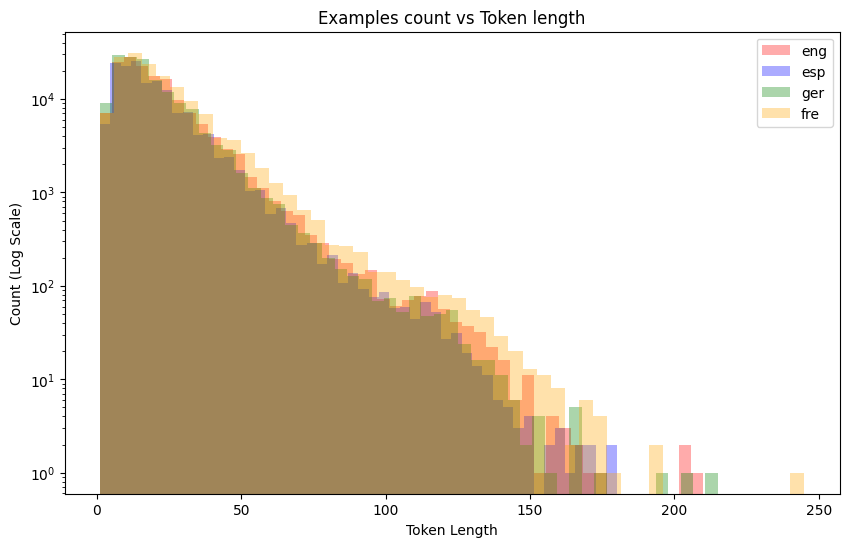

In [42]:
def visualize_data(df):
    print("--- Visualizing Data ---")
    # Histogram of sentence length in tokens
    # Note: Just splitting by space as a rough approximation similar to original notebook
    eng_length = [len(str(sentence).split()) for sentence in df["english"].dropna()]
    esp_length = [len(str(sentence).split()) for sentence in df["spanish"].dropna()]
    ger_length = [len(str(sentence).split()) for sentence in df["german"].dropna()]
    fre_length = [len(str(sentence).split()) for sentence in df["french"].dropna()]

    plt.figure(figsize=(10, 6))
    plt.hist(eng_length, label="eng", color="red", alpha=0.33, bins=50)
    plt.hist(esp_length, label="esp", color="blue", alpha=0.33, bins=50)
    plt.hist(ger_length, label="ger", color="green", alpha=0.33, bins=50)
    plt.hist(fre_length, label="fre", color="orange", alpha=0.33, bins=50)
    
    plt.yscale("log") 
    plt.legend()
    plt.title("Examples count vs Token length")
    plt.xlabel("Token Length")
    plt.ylabel("Count (Log Scale)")
    plt.show()

visualize_data(dataset)

In [43]:
def train_bpe(df):
    """Train BPE on lowercased English+Spanish so vocab is not split across cases."""
    if os.path.exists(config.BPE_MODEL_PREFIX + ".json"):
        return Tokenizer.from_file(config.BPE_MODEL_PREFIX + ".json")

    print("Training BPE model on lowercased corpus...")
    combined_iterator = itertools.chain(
        (s.lower() for s in df['english'].astype(str)),
        (s.lower() for s in df['french'].astype(str)),
        (s.lower() for s in df['german'].astype(str)),
        (s.lower() for s in df['spanish'].astype(str)),
    )
    bpe_tokeniser = Tokenizer(models.BPE(unk_token="<unk>"))
    bpe_tokeniser.normalizer = normalizers.Sequence([
        normalizers.NFC(),
        normalizers.Lowercase(),
    ])
    bpe_tokeniser.pre_tokenizer = pre_tokenizers.Sequence([
        pre_tokenizers.Whitespace(),
        pre_tokenizers.Digits(individual_digits=True),
    ])
    bpe_trainer = trainers.BpeTrainer(
        vocab_size=config.MIX_VOCAB_SIZE,
        special_tokens=["<pad>", "<unk>", "<bos>", "<eos>", "<to_fr>", "<to_de>", "<to_es>"],
        show_progress=True,
    )
    bpe_tokeniser.train_from_iterator(combined_iterator, trainer=bpe_trainer)
    bpe_tokeniser.save(config.BPE_MODEL_PREFIX + ".json")
    return bpe_tokeniser

bpe_tok = train_bpe(dataset)
print("Sample tokens:", bpe_tok.encode("Hello World").tokens)
print("Sample with specials:", bpe_tok.encode("<bos> <to_fr> hola mundo <eos>").ids)

train_df, valid_df = train_test_split(dataset, test_size=0.2, random_state=42)
print(train_df.shape, valid_df.shape)

Training BPE model on lowercased corpus...



Sample tokens: ['hello', 'world']
Sample with specials: [2, 4, 11910, 1046, 3]
(123626, 4) (30907, 4)


In [44]:
def tokenize_dataset(df, bpe_tokeniser):
    # 1. Prepare Data (Vectorized String Operations)
    # Using specific columns avoids copying the whole DF
    print("Preparing string data...")
    
    # Process French
    df_fr = df[["english", "french"]].dropna().copy()
    df_fr["source"] = ("<to_fr> " + df_fr["english"]).str.lower()
    df_fr["target"] = df_fr["french"].str.lower()
    
    # Process German
    df_de = df[["english", "german"]].dropna().copy()
    df_de["source"] = ("<to_de> " + df_de["english"]).str.lower()
    df_de["target"] = df_de["german"].str.lower()
    
    # Process Spanish
    df_es = df[["english", "spanish"]].dropna().copy()
    df_es["source"] = ("<to_es> " + df_es["english"]).str.lower()
    df_es["target"] = df_es["spanish"].str.lower()

    # Concatenate once
    final_df = pd.concat([df_fr[["source", "target"]], 
                          df_de[["source", "target"]], 
                          df_es[["source", "target"]]], ignore_index=True)
    
    print(f"Final shape of raw dataset: {final_df.shape}")

    # 2. Batch Tokenization (The Speedup)
    # Convert to list for the tokenizer (much faster than iterating series)
    source_texts = final_df["source"].tolist()
    # Add BOS/EOS to targets via list comprehension (faster than pandas apply)
    target_texts = ["<bos> " + t + " <eos>" for t in final_df["target"].tolist()]

    print("Tokenizing in batches...")
    
    # encode_batch runs in Rust and uses multi-threading
    source_encodings = bpe_tokeniser.encode_batch(source_texts)
    target_encodings = bpe_tokeniser.encode_batch(target_texts)

    # 3. Extract IDs and Filter (Vectorized)
    # Extract IDs from the Encoding objects
    final_df["source_ids"] = [e.ids for e in source_encodings]
    final_df["target_ids"] = [e.ids for e in target_encodings]
    
    # Calculate lengths efficiently
    final_df["src_len"] = final_df["source_ids"].map(len)
    final_df["tgt_len"] = final_df["target_ids"].map(len)

    # Filter using boolean masking (Vectorized)
    mask = (final_df["src_len"] <= config.MAX_LENGTH) & \
           (final_df["tgt_len"] <= config.MAX_LENGTH + 1)
    
    filtered_df = final_df.loc[mask, ["source_ids", "target_ids"]].rename(
        columns={"source_ids": "source", "target_ids": "target"}
    ).reset_index(drop=True)

    print(f"Filtered and Tokenized {len(filtered_df)} samples")
    return filtered_df

train_df = tokenize_dataset(train_df, bpe_tok)
valid_df = tokenize_dataset(valid_df, bpe_tok)

Preparing string data...
Final shape of raw dataset: (370878, 2)
Tokenizing in batches...
Filtered and Tokenized 368025 samples
Preparing string data...
Final shape of raw dataset: (92721, 2)
Tokenizing in batches...
Filtered and Tokenized 91983 samples


In [ ]:
def serialize_example(src, trg):
    feature = {
        "source": tf.train.Feature(int64_list=tf.train.Int64List(value=src)),
        "target": tf.train.Feature(int64_list=tf.train.Int64List(value=trg)),
    }
    return tf.train.Example(features=tf.train.Features(feature=feature)).SerializeToString()

def parse_fn(example):
    feature_description = {
        "source": tf.io.VarLenFeature(tf.int64),
        "target": tf.io.VarLenFeature(tf.int64),
    }
    example = tf.io.parse_single_example(example, feature_description)
    src = tf.sparse.to_dense(example["source"])
    trg = tf.sparse.to_dense(example["target"])
    return src, trg

def create_tfrecords(dataset, filename):
    with tf.io.TFRecordWriter(filename) as writer:
        for s, t in dataset.itertuples(index=False):
            writer.write(serialize_example(s, t))

def split_target(src, trg):
    return src, trg[:-1], trg[1:]

create_tfrecords(train_df, config.TF_RECORD_TRAIN)
create_tfrecords(valid_df, config.TF_RECORD_VAL)

train_dataset_raw = (
    tf.data.TFRecordDataset(config.TF_RECORD_TRAIN)
    .map(parse_fn, num_parallel_calls=tf.data.AUTOTUNE)
    .map(split_target, num_parallel_calls=tf.data.AUTOTUNE)
)

valid_dataset_raw = (
    tf.data.TFRecordDataset(config.TF_RECORD_VAL)
    .map(parse_fn, num_parallel_calls=tf.data.AUTOTUNE)
    .map(split_target, num_parallel_calls=tf.data.AUTOTUNE)
)

In [ ]:
num_replicas = strategy.num_replicas_in_sync

BUFFER_SIZE = 10000
TOKENS_PER_BATCH = 4096
TOKENS_PER_BATCH = TOKENS_PER_BATCH * num_replicas

def element_length_func(inputs, targets):
    return tf.shape(inputs["encoder_inputs"])[0]

def format_dataset(src, trg_in, trg_out):
    return ({"encoder_inputs": src, "decoder_inputs": trg_in}, trg_out)

bucket_boundaries = [16, 32, 64, 96]
bucket_batch_sizes = [int(TOKENS_PER_BATCH / x) for x in bucket_boundaries]
bucket_batch_sizes.append(int(TOKENS_PER_BATCH / 100))
print(f"Bucket batch sizes: {bucket_batch_sizes}")
# -> [256, 128, 64, 42, 40]

train_ds = (
    train_dataset_raw
    .map(format_dataset, num_parallel_calls=tf.data.AUTOTUNE)
    .cache()
    .shuffle(BUFFER_SIZE)
    .bucket_by_sequence_length(
        element_length_func=element_length_func,
        bucket_boundaries=bucket_boundaries,
        bucket_batch_sizes=bucket_batch_sizes,
        padding_values=(
            {"encoder_inputs": tf.constant(0, dtype=tf.int64),
             "decoder_inputs": tf.constant(0, dtype=tf.int64)},
            tf.constant(0, dtype=tf.int64)
        ),
        drop_remainder=True,
    )
    .prefetch(tf.data.AUTOTUNE)
)

valid_ds = (
    valid_dataset_raw
    .map(format_dataset, num_parallel_calls=tf.data.AUTOTUNE)
    .bucket_by_sequence_length(
        element_length_func=element_length_func,
        bucket_boundaries=bucket_boundaries,
        bucket_batch_sizes=bucket_batch_sizes,
        padding_values=(
            {"encoder_inputs": tf.constant(0, dtype=tf.int64),
             "decoder_inputs": tf.constant(0, dtype=tf.int64)},
            tf.constant(0, dtype=tf.int64)
        ),
        drop_remainder=True,
    )
    .prefetch(tf.data.AUTOTUNE)
)

print("Data pipelines created successfully using the stable API.")

Bucket batch sizes: [512, 256, 128, 85, 81]
Data pipelines created successfully using the stable API.


In [ ]:
# --- 3. Model Architecture (paper-standard: padding masks, scaled embeddings,
# proper key_dim per head, weight tying) ---

class PositionalEmbedding(Layer):
    def __init__(self, sequence_length, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.sequence_length = sequence_length
        self.embed_dim = embed_dim
        self.pos_encoding = self.positional_encoding(sequence_length, embed_dim)

    def get_angles(self, pos, i, d_model):
        angles = 1 / np.power(10000, (2 * (i // 2)) / np.float32(d_model))
        return pos * angles

    def positional_encoding(self, position, d_model):
        angle_rads = self.get_angles(
            np.arange(position)[:, np.newaxis],
            np.arange(d_model)[np.newaxis, :],
            d_model
        )
        angle_rads[:, 0::2] = np.sin(angle_rads[:, 0::2])
        angle_rads[:, 1::2] = np.cos(angle_rads[:, 1::2])
        pos_encoding = angle_rads[np.newaxis, ...]
        return tf.cast(pos_encoding, dtype=tf.float32)

    def call(self, inputs):
        if getattr(inputs, 'sparse', False) or isinstance(inputs, tf.SparseTensor):
            inputs = tf.sparse.to_dense(inputs)
            
        length = tf.shape(inputs)[1]
        return inputs + self.pos_encoding[:, :length, :]


class TransformerEncoder(Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, drop_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.att = MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim // num_heads)
        self.ffn = Sequential([
            Dense(ff_dim, activation="relu"),
            Dense(embed_dim),
        ])
        self.layernorm1 = LayerNormalization(epsilon=1e-6)
        self.layernorm2 = LayerNormalization(epsilon=1e-6)
        self.dropout1 = Dropout(drop_rate)
        self.dropout2 = Dropout(drop_rate)

    def call(self, inputs, padding_mask=None, training=False):
        attn_output = self.att(inputs, inputs, attention_mask=padding_mask)
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(inputs + attn_output)
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)


class TransformerDecoder(Layer):
    def __init__(self, embed_dim, ff_dim, num_heads, drop_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.att1 = MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim // num_heads)
        self.att2 = MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim // num_heads)
        self.ffn = Sequential([
            Dense(ff_dim, activation="relu"),
            Dense(embed_dim),
        ])
        self.layernorm1 = LayerNormalization(epsilon=1e-6)
        self.layernorm2 = LayerNormalization(epsilon=1e-6)
        self.layernorm3 = LayerNormalization(epsilon=1e-6)
        self.dropout1 = Dropout(drop_rate)
        self.dropout2 = Dropout(drop_rate)
        self.dropout3 = Dropout(drop_rate)

    def get_causal_attention_mask(self, inputs):
        batch_size = tf.shape(inputs)[0]
        sequence_length = tf.shape(inputs)[1]

        mask = tf.linalg.band_part(
            tf.ones((sequence_length, sequence_length), dtype=tf.int32),
            -1,
            0
        )

        mask = mask[tf.newaxis, :, :]
        return tf.tile(mask, [batch_size, 1, 1])

    def call(self, inputs, encoder_outputs,
             encoder_padding_mask=None, decoder_padding_mask=None, training=False):
        causal_mask = self.get_causal_attention_mask(inputs)
        if decoder_padding_mask is not None:
            combined_mask = tf.minimum(causal_mask, decoder_padding_mask)
        else:
            combined_mask = causal_mask

        att1_output = self.att1(inputs, inputs, attention_mask=combined_mask)
        att1_output = self.dropout1(att1_output, training=training)
        out1 = self.layernorm1(inputs + att1_output)

        att2_output = self.att2(out1, encoder_outputs, attention_mask=encoder_padding_mask)
        att2_output = self.dropout2(att2_output, training=training)
        out2 = self.layernorm2(out1 + att2_output)

        ffn_output = self.ffn(out2)
        ffn_output = self.dropout3(ffn_output, training=training)
        return self.layernorm3(out2 + ffn_output)


class PaddingMask(Layer):
    """Returns (batch, 1, seq) mask: 1 for real tokens, 0 for <pad> (id 0)."""
    def call(self, inputs):
        return tf.cast(tf.not_equal(inputs, 0), tf.int32)[:, tf.newaxis, :]


class TiedOutputProjection(Layer):
    """Output projection that reuses the embedding matrix (weight tying)."""
    def __init__(self, embedding_layer, **kwargs):
        super().__init__(**kwargs)
        self.embedding_layer = embedding_layer

    def call(self, inputs):
        return tf.matmul(inputs, self.embedding_layer.embeddings, transpose_b=True)

    def get_config(self):
        config = super().get_config()
        # Serialize the embedding layer config natively
        # Keras will intelligently track shared objects without duplicating weights
        config.update({
            "embedding_layer": tf.keras.saving.serialize_keras_object(self.embedding_layer)
        })
        return config

    @classmethod
    def from_config(cls, config):
        # Pop out the embedding layer config and deserialize it
        embedding_layer_config = config.pop("embedding_layer")
        embedding_layer = tf.keras.saving.deserialize_keras_object(embedding_layer_config)
        # Pass the initialized layer and the remaining config arguments
        return cls(embedding_layer=embedding_layer, **config)


class CustomSchedule(tf.keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, d_model, warmup_steps=4000):
        super().__init__()
        self.d_model = tf.cast(d_model, tf.float32)
        self.warmup_steps = warmup_steps

    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        arg1 = tf.math.rsqrt(step)
        arg2 = step * (self.warmup_steps ** -1.5)
        return tf.math.rsqrt(self.d_model) * tf.math.minimum(arg1, arg2)


def build_transformer(config):
    encoder_inputs = Input(shape=(None,), dtype="int64", name="encoder_inputs")
    decoder_inputs = Input(shape=(None,), dtype="int64", name="decoder_inputs")
    
    enc_padding_mask = PaddingMask(name="enc_padding_mask")(encoder_inputs)
    dec_padding_mask = PaddingMask(name="dec_padding_mask")(decoder_inputs)
    
    shared_embedding = Embedding(
        config.MIX_VOCAB_SIZE, 
        config.EMBED_DIM, 
        name="shared_embedding",
    )
    
    # Compute scale as a Python float, not a tensor op
    scale = config.EMBED_DIM ** 0.5  # plain Python float, avoids sparse issues
    
    # Encoder
    x = shared_embedding(encoder_inputs)
    x = x * scale
    x = PositionalEmbedding(config.MAX_LENGTH, config.EMBED_DIM)(x)
    x = Dropout(config.DROPOUT_RATE)(x)
    for _ in range(config.NUM_ENCODER_LAYERS):
        x = TransformerEncoder(
            config.EMBED_DIM, config.NUM_HEADS, config.FF_DIM, config.DROPOUT_RATE
        )(x, padding_mask=enc_padding_mask)
    encoder_outputs = x
    
    # Decoder
    y = shared_embedding(decoder_inputs)
    y = y * scale
    y = PositionalEmbedding(config.MAX_LENGTH, config.EMBED_DIM)(y)
    y = Dropout(config.DROPOUT_RATE)(y)
    for _ in range(config.NUM_DECODER_LAYERS):
        y = TransformerDecoder(
            config.EMBED_DIM, config.FF_DIM, config.NUM_HEADS, config.DROPOUT_RATE
        )(
            y, encoder_outputs,
            encoder_padding_mask=enc_padding_mask,
            decoder_padding_mask=dec_padding_mask,
        )
    
    decoder_outputs = TiedOutputProjection(
        shared_embedding, name="output_projection"
    )(y)
    
    return Model([encoder_inputs, decoder_inputs], decoder_outputs, name="transformer")

In [ ]:
LABEL_SMOOTHING = 0.1


def masked_loss(real, pred):
    # real: (batch, seq)   pred: (batch, seq, vocab) -- LOGITS
    real = tf.cast(real, tf.int32) 
    
    vocab_size = tf.shape(pred)[-1]
    real_one_hot = tf.one_hot(real, depth=vocab_size, dtype=pred.dtype)

    smooth_targets = real_one_hot * (1.0 - LABEL_SMOOTHING) + \
                     LABEL_SMOOTHING / tf.cast(vocab_size, pred.dtype)

    log_probs = tf.nn.log_softmax(pred, axis=-1)
    loss_per_token = -tf.reduce_sum(smooth_targets * log_probs, axis=-1)

    mask = tf.cast(tf.not_equal(real, 0), loss_per_token.dtype)
    loss_per_token *= mask
    return tf.reduce_sum(loss_per_token) / tf.reduce_sum(mask)


def masked_accuracy(real, pred):
    pred_ids = tf.argmax(pred, axis=2)
    real = tf.cast(real, pred_ids.dtype)
    is_correct = tf.equal(real, pred_ids)

    mask = tf.math.logical_not(tf.math.equal(real, 0))
    is_correct = tf.math.logical_and(mask, is_correct)

    is_correct = tf.cast(is_correct, dtype=tf.float32)
    mask = tf.cast(mask, dtype=tf.float32)
    return tf.reduce_sum(is_correct) / tf.reduce_sum(mask)

In [ ]:
with strategy.scope():
    transformer = build_transformer(config)
    learning_rate = CustomSchedule(config.EMBED_DIM)
    optimizer = Adam(
        learning_rate,
        beta_1=0.9,
        beta_2=0.98,
        epsilon=1e-9
    )

    transformer.compile(
        optimizer=optimizer,
        loss=masked_loss,
        metrics=[masked_accuracy]
    )

    transformer.summary()

Model: "transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ decoder_inputs      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_inputs      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_embedding    │ (None, None, 512) │ 16,384,000 │ encoder_inputs[0… │
│ (Embedding)         │                   │            │ decoder_inputs[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_8          │ (None, None, 512) │          0 │ shared_embedding… │
│ (Multiply)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, None, 512) │          0 │ multiply_8[0][0]  │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_154         │ (None, None, 512) │          0 │ positional_embed… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_padding_mask    │ (None, 1, None)   │          0 │ encoder_inputs[0… │
│ (PaddingMask)       │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encode… │ (None, None, 512) │  2,627,584 │ dropout_154[0][0… │
│ (TransformerEncode… │                   │            │ enc_padding_mask… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encode… │ (None, None, 512) │  2,627,584 │ transformer_enco… │
│ (TransformerEncode… │                   │            │ enc_padding_mask… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encode… │ (None, None, 512) │  2,627,584 │ transformer_enco… │
│ (TransformerEncode… │                   │            │ enc_padding_mask… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_9          │ (None, None, 512) │          0 │ shared_embedding… │
│ (Multiply)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encode… │ (None, None, 512) │  2,627,584 │ transformer_enco… │
│ (TransformerEncode… │                   │            │ enc_padding_mask… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, None, 512) │          0 │ multiply_9[0][0]  │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encode… │ (None, None, 512) │  2,627,584 │ transformer_enco… │
│ (TransformerEncode… │                   │            │ enc_padding_mask… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_173         │ (None, None, 512) │          0 │ positional_embed… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encode… │ (None, None, 512) │  2,627,584 │ transformer_enco… │
│ (TransformerEncode… │                   │            │ enc_padding_mask… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_padding_mask    │ (None, 1, None)   │          0 │ decoder_inputs[0

 Total params: 54,224,896 (206.85 MB)

 Trainable params: 54,224,896 (206.85 MB)

 Non-trainable params: 0 (0.00 B)

In [50]:
model_name = "transformer_model_multi.weights.h5"

if config.IS_TRAINING:
    checkpoints = ModelCheckpoint(
        model_name,
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
    )

    early_stop = EarlyStopping(
        patience=7,
        monitor="val_loss",
        mode="min",
        restore_best_weights=True,
    )

    history = transformer.fit(
        train_ds,
        epochs=config.EPOCHS,
        validation_data=valid_ds,
        callbacks=[checkpoints, early_stop],
    )

else:
    try:
        transformer.load_weights(model_name)
    except (FileNotFoundError, tf.errors.NotFoundError):
        print(f"Error: weights file {model_name} not found. Set config.IS_TRAINING = True first.")

Epoch 1/100
INFO:tensorflow:Collective all_reduce tensors: 253 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1


2026-05-17 16:51:54.828454: E tensorflow/core/common_runtime/base_collective_executor.cc:248] BaseCollectiveExecutor::StartAbort INVALID_ARGUMENT: Shape mismatch in the collective instance 100. Op at device /job:localhost/replica:0/task:0/device:GPU:0 expected shape [54224896] but another member in the group expected shape [39735296]. This is likely due to different input shapes at different members of the collective op.


InvalidArgumentError: Graph execution error:

Detected at node cond/adam/CollectiveReduceV2 defined at (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main

  File "<frozen runpy>", line 88, in _run_code

  File "/usr/local/lib/python3.12/dist-packages/colab_kernel_launcher.py", line 37, in <module>

  File "/usr/local/lib/python3.12/dist-packages/traitlets/config/application.py", line 1075, in launch_instance

  File "/usr/local/lib/python3.12/dist-packages/ipykernel/kernelapp.py", line 712, in start

  File "/usr/local/lib/python3.12/dist-packages/tornado/platform/asyncio.py", line 211, in start

  File "/usr/lib/python3.12/asyncio/base_events.py", line 645, in run_forever

  File "/usr/lib/python3.12/asyncio/base_events.py", line 1999, in _run_once

  File "/usr/lib/python3.12/asyncio/events.py", line 88, in _run

  File "/usr/local/lib/python3.12/dist-packages/ipykernel/kernelbase.py", line 510, in dispatch_queue

  File "/usr/local/lib/python3.12/dist

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(10, 6))
plt.plot(history.history['masked_accuracy'], label='Training Accuracy')
plt.plot(history.history['val_masked_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy Over Epochs')
plt.xlabel('Epoch'); plt.ylabel('Accuracy')
plt.legend(); plt.grid(True); plt.show()

In [ ]:
import tensorflow as tf

def translate(input_sentence, model, tokenizer, config):
    """
    Translates a sentence using Greedy Decoding.
    """
    # 1. Preprocess the source sentence
    text = f"{input_sentence}".lower()
    input_ids = tokenizer.encode(text).ids

    # Truncate if too long
    if len(input_ids) > config.MAX_LENGTH:
        input_ids = input_ids[:config.MAX_LENGTH]

    encoder_input = tf.convert_to_tensor([input_ids], dtype=tf.int64)

    # 2. Initialize the decoder with <bos>
    bos_id = tokenizer.token_to_id("<bos>")
    eos_id = tokenizer.token_to_id("<eos>")
    decoder_input = [bos_id]

    print(f"Translating: '{input_sentence}'...")

    # 3. Generation loop
    for i in range(config.MAX_LENGTH):
        decoder_tensor = tf.convert_to_tensor([decoder_input], dtype=tf.int64)
        predictions = model([encoder_input, decoder_tensor], training=False)

        # Logits for the LAST token only -> shape (1, 1, vocab_size)
        last_token_logits = predictions[:, -1:, :]

        # Greedy: highest-logit token
        predicted_id = tf.argmax(last_token_logits, axis=-1).numpy()[0][0]

        # Stop if model emits <eos>
        if predicted_id == eos_id:
            break

        decoder_input.append(predicted_id)

    # 4. Decode (skip the leading <bos>)
    result_ids = decoder_input[1:]
    return tokenizer.decode(result_ids)

In [ ]:
es_text = translate("<to_es> I want to go to the library.", transformer, bpe_tok, config)
print(f"Spanish: {es_text}")

In [ ]:
import tensorflow as tf

class BeamTranslator:
    def __init__(self, model, tokenizer, beam_width=5, max_length=60, alpha=0.6):
        self.model = model
        self.tokenizer = tokenizer
        self.beam_width = beam_width
        self.max_length = max_length
        self.alpha = alpha  # Length penalty factor (0.6 is standard)

        self.bos_id = tokenizer.token_to_id("<bos>")
        self.eos_id = tokenizer.token_to_id("<eos>")
        if self.bos_id is None: self.bos_id = 2
        if self.eos_id is None: self.eos_id = 3

    def calc_length_penalty(self, length):
        """Google NMT length penalty — prevents bias toward short translations."""
        return ((5 + length) / 6) ** self.alpha

    def translate(self, sentence):
        # 1. Preprocess source
        sentence = sentence.lower()
        input_ids = self.tokenizer.encode(sentence).ids
        encoder_input = tf.constant([input_ids], dtype=tf.int64)

        # 2. Initialize the beam: (score, sequence)
        beams = [(0.0, [self.bos_id])]
        completed_sequences = []

        # 3. Decoding loop
        for _ in range(self.max_length):
            candidates = []
            for score, seq in beams:
                # Don't expand beams that already ended
                if seq[-1] == self.eos_id:
                    completed_sequences.append((score, seq))
                    continue

                decoder_input = tf.constant([seq], dtype=tf.int64)
                predictions = self.model([encoder_input, decoder_input], training=False)

                # Logits -> log-probs for the LAST token
                last_token_logits = predictions[:, -1, :]
                log_probs = tf.nn.log_softmax(last_token_logits, axis=-1)

                top_k_log_probs, top_k_ids = tf.math.top_k(log_probs, k=self.beam_width)
                top_k_log_probs = top_k_log_probs.numpy()[0]
                top_k_ids = top_k_ids.numpy()[0]

                for i in range(self.beam_width):
                    token_id = top_k_ids[i]
                    log_prob = top_k_log_probs[i]
                    new_score = score + log_prob
                    new_seq = seq + [token_id]
                    candidates.append((new_score, new_seq))

            candidates.sort(key=lambda x: x[0], reverse=True)
            beams = candidates[:self.beam_width]

            if all(seq[-1] == self.eos_id for _, seq in beams):
                break

        # 4. Final ranking with length penalty
        completed_sequences.extend(beams)
        final_candidates = []
        for score, seq in completed_sequences:
            length_penalty = self.calc_length_penalty(len(seq))
            final_score = score / length_penalty
            final_candidates.append((final_score, seq))

        final_candidates.sort(key=lambda x: x[0], reverse=True)
        best_seq = final_candidates[0][1]

        # 5. Strip BOS/EOS and decode
        if best_seq[0] == self.bos_id: best_seq = best_seq[1:]
        if best_seq and best_seq[-1] == self.eos_id: best_seq = best_seq[:-1]
        return self.tokenizer.decode(best_seq)

In [ ]:
translator = BeamTranslator(
    model=transformer,
    tokenizer=bpe_tok,
    beam_width=5,
    alpha=0.6,
)

sentences = [
    "<to_fr> Hello, how are you?",
    "<to_de> The car is very fast.",
    "<to_es> I want to go to the library.",
]

for sent in sentences:
    translation = translator.translate(sent)
    print(f"Input:  {sent}")
    print(f"Output: {translation}")
    print("-" * 30)